# 04 · Mechanisms (Phase 3)

Phase 2 closed the rebound story: the 1st-half surge (+0.079 EPA/play in the last 4:00, starting around 3:00) is the same size whether a team struggled earlier or not. That isn't a dead end. **A boost every team gets is still a finding**, and it changes the question from "who rebounds?" to **"what changes late in the 1st half for everyone, and who gets more or less of it?"**

Order of attack (doc §8, v1.5): check that the surge is real on raw outcomes before blaming anything on a mechanism → composition (H8) → no-huddle/pace (H1) → game state (H7) → load extra data → soft coverage (H2), personnel (H5), play-calling (H3), clock/timeouts (H4), defensive subs (H6) → heterogeneity → one joint ladder → scoreboard.

Every test and its evidence rule is written in the next cell, before any output. The *Reading* cells are where we write down what came out.

## Phase 3 pre-specification (doc v1.5, 2026-11-19)

Written before any Phase 3 outcome was looked at. Anything changed after this point gets logged with date and reason.

### Framing
Phase 2 showed the 1st-half surge is not a rebound: struggling and non-struggling teams get the same boost. A boost that goes to everyone is still a finding, and arguably a bigger one. So Phase 3 asks two things: **(1) why does a surge show up for every team state**, and **(2) who gets more or less of it** (heterogeneity), not only whether some mechanism exists.

### Fixed rules
- Unit is the play. 1st half is primary, 2nd half is a comparison where it's cheap. Late = 240 s or less left, rest = the half's B0-B2 plays (unchanged from Phase 1).
- Headline quantity: late minus rest in EPA/play, 1st half (Phase 1: +0.079). Notebook 04 re-derives it first as a check on the new code.
- Intervals: 95% percentile bootstrap, resampling whole games, 1,000 draws.
- **Mix vs within.** For a play characteristic X (no-huddle, pass/run, score state...), late-minus-rest = *mix* + *within*. Mix = what the gap would be if the only change late were a shift in how many plays of each X-type there are, valued at rest-of-half performance. Within = like-for-like gap with X held fixed. **Explained share = mix / total gap.** This is accounting, not causation.
- **Verdict rule** (on the marginal share, one variable at a time): *main driver* if share >= 50% and its lower bound > 25%; *contributor* if lower bound > 10%; *ruled out* if upper bound < 20%; otherwise *unclear*. Incremental share in the ladder (Step 12) is reported next to it, because correlated variables (e.g. no-huddle and trailing) share credit.
- Order: Step 1 first. If the surge disappears on raw outcomes, stop the mechanism chase and reframe.
- Hypotheses that need participation/FTN data (H2, H5 personnel, H6) are only tested on seasons where those fields exist. If a field isn't there, the test is reported as "cannot test", not guessed.

### Hypotheses, tests, rules
| # | Idea | Primary test | Secondary | Evidence rule |
|---|------|--------------|-----------|---------------|
| Step 1 | Measurement: late EPA has a different baseline (EPA model knows the clock) | Late-minus-rest on raw outcomes: yards/play, first-down-or-TD rate, down-and-distance success (no EPA), explosive rate, turnover, sack; raw and like-for-like on down x distance | By bucket | Surge "survives" if first-down rate, raw success and yards/play gaps are all positive with lower bound > 0. If none are, it's an EPA artifact: stop and reframe. Mixed = partly artifact. |
| H8 | Composition: better offenses / weaker defenses / better game states have the ball late | (a) team-quality composition: gap in offense quality + opposing-defense quality (season EPA, built without 1st-half late plays); (b) gap within the same team in the same game-half (fixed effects) | Home share | Supported if composition-predicted share >= 50% or the fixed-effects gap <= half the raw gap. Ruled out if both < 20%. |
| H1 | No-huddle / pace | Marginal mix share by `no_huddle` flag | Surge among huddle-only plays; no-huddle vs huddle like-for-like (down x distance x score state); clean snap-to-snap tempo late vs rest; mix share by tempo tercile; fast vs slow tempo like-for-like | Verdict rule on the no-huddle share. If the surge is as big on huddle-only plays and tempo shows no late speed-up, pace is out. |
| H7 | Game state (leader vs trailer, urgency) | Marginal mix share by score-state (5 bins) | Late gap within each state, both halves; 2nd-half state x season table for the 2024-25 flip | Verdict rule. Also: if the gap is similar in every state, state is not the engine. |
| H2 | Prevent / soft coverage | Marginal mix share by defensive shell (DB count x pass rushers) on pass plays | Coverage type, man/zone, surge on non-soft plays only (<= 5 DBs and >= 4 rushers), pbp proxies (completion %, air yards, sacks) | Verdict rule. Without participation data: "cannot test", pbp proxies reported as indirect evidence only. |
| H5 | Personnel / formation | Marginal mix share by personnel (RB/TE counts) x shotgun | WR count, shotgun alone (pbp only) | Verdict rule. |
| H3 | Play-calling | Marginal mix share by pass vs run | Pass-depth mix (air yards bins), play-action/screen/motion/RPO rates (FTN, 2022+) | Verdict rule. |
| H4 | Clock / timeouts / two-minute warning | Within the late window, plays with >= 2 timeouts vs <= 1, like-for-like (down x distance x score state) | 30-second slice profile of EPA vs rest, to see whether the jump sits at 3:00 or at the 2:00 warning | Supported if the >= 2 timeouts group is higher by >= 0.03 EPA/play with lower bound > 0. Slice profile is descriptive. |
| H6 | Defensive substitution limits | Two links: (i) defense subs less often late (any_sub rate, clean-clock plays), (ii) plays where the defense didn't sub have higher EPA like-for-like | Mix share by any_sub; any_sub by tempo tercile | Supported only if both links hold (i: late any_sub rate lower with CI excluding 0; ii: difference > 0 with lower bound > 0) and mix share lower bound > 10%. |

### Heterogeneity (question 2)
Late-minus-rest gap by: offense-quality third, defense-quality third, pass-leaning third, home/away. Difference between extreme levels with a joint bootstrap. Descriptive; no verdict rule.

### Joint accounting
Ladder of regressions, EPA ~ late + controls, controls added in this order: down/distance/field position, score state, pass/run, no-huddle, shotgun, (personnel where available), then team-game-half fixed effects. Coefficient on `late` after each step, with the share of the raw gap each step removes. Order matters: this is a way to see how much is left, not a ranking.

### Known limits (written now so they aren't discovered later)
- Tempo is endogenous (teams going well play faster), so tempo and no-huddle results are associations. Snap-to-snap clock time is only used on clean intervals (prior play completed in bounds, no penalty, no timeout, not across the 2:00 warning, 8-45 s); unseen no-plays can still slip in.
- Participation and FTN charting cover only some seasons. FTN data requires attribution (FTN Data via nflverse, CC-BY-SA 4.0) in the write-up.
- "Explained share" is accounting and can exceed 100% or go negative; controlling for a mediator (e.g. pass/run) removes a mechanism's effect rather than a confound.

## Setup
Same data as notebooks 02-03. Everything is play-level from `plays.parquet`; drives aren't needed here.

In [1]:
import re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 70)
plt.rcParams.update({"axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "lines.linewidth": 1.3, "figure.dpi": 110})
BLUE, ORANGE = "#2a78d6", "#eb6834"

DATA = Path("../data")
NBOOT = 1000   # bootstrap draws; drop to 300 while iterating
SEED = 7

plays = pd.read_parquet(DATA / "plays.parquet")
print(plays.shape)

(326039, 374)


### Comparison engine
Two tools, both bootstrapped by resampling whole games (§ fixed rules):

- `gap(d, metric, flag, cells)` compares flag=1 plays (default: late) with flag=0 plays (rest). With `cells`, it also splits the gap into **mix** (late has more plays of some type) and **within** (like-for-like gap inside each type). `share` = mix / total. Fast trick: per game we only store counts and sums per cell, then each bootstrap draw is just a weighted sum of games.
- `ols_late(d, ctrl, fe)` is a regression `metric ~ late + dummies(ctrl)`, optionally with fixed effects. The coefficient on `late` = late minus rest *after holding the controls fixed*. Same game-level trick: per game we store `X'X` and `X'y`, so each bootstrap draw is one small matrix solve.

In [2]:
_W = {}
def _weights(G, nboot, seed=SEED):
    """Multinomial game weights: row b says how many times each game is drawn."""
    key = (G, nboot, seed)
    if key not in _W:
        if len(_W) > 8:
            _W.clear()
        rng = np.random.default_rng(seed)
        _W[key] = rng.multinomial(G, np.full(G, 1 / G), size=nboot).astype(float)
    return _W[key]

def boot(X, fn, nboot=None):
    """X: games x sums. fn maps summed rows (n x k) to a dict of arrays. Returns est / lo / hi."""
    nboot = nboot or NBOOT
    pt, dr = fn(X.sum(0, keepdims=True)), fn(_weights(len(X), nboot) @ X)
    out = {k: (float(np.ravel(pt[k])[0]), *np.nanpercentile(dr[k], [2.5, 97.5])) for k in pt}
    return pd.DataFrame(out, index=["est", "lo", "hi"]).T

def cellkey(d, cols):
    k = d[cols[0]].astype(str)
    for c in cols[1:]:
        k = k + "|" + d[c].astype(str)
    return k

def cell_S(d, metric, flag, cell, games):
    """Per-game counts and sums by cell for flag=1 and flag=0. Columns: [n1 | n0 | s1 | s0], one block per cell."""
    cell = np.full(len(d), "all") if cell is None else cell
    t = pd.DataFrame({"g": d["game_id"].to_numpy(), "c": cell,
                      "f": d[flag].to_numpy().astype(int), "m": d[metric].to_numpy(float)})
    a = t.groupby(["g", "c", "f"], sort=False)["m"].agg(["size", "sum"]).reset_index()
    cl = np.sort(a["c"].unique())
    gi, ci_ = games.get_indexer(a["g"]), pd.Index(cl).get_indexer(a["c"])
    N = np.zeros((2, len(games), len(cl)))
    S = np.zeros_like(N)
    f = a["f"].to_numpy()
    N[f, gi, ci_] = a["size"].to_numpy()
    S[f, gi, ci_] = a["sum"].to_numpy()
    return np.concatenate([N[1], N[0], S[1], S[0]], axis=1), cl

def _decomp(C):
    def fn(T):
        n1, n0, s1, s0 = (T[:, i * C:(i + 1) * C] for i in range(4))
        N1, N0 = n1.sum(1), n0.sum(1)
        with np.errstate(divide="ignore", invalid="ignore"):
            g1, g0 = s1.sum(1) / N1, s0.sum(1) / N0
            ok = (n1 > 0) & (n0 > 0)                       # common support: cells seen in both groups
            w = np.where(ok, n1 / N1[:, None], 0.0)        # weight cells by the flag=1 (late) mix
            within = np.where(ok, w * (s1 / n1 - s0 / n0), 0.0).sum(1) / w.sum(1)
            total = g1 - g0
            return {"g1": g1, "g0": g0, "total": total, "within": within,
                    "mix": total - within, "share": (total - within) / total}
    return fn

def _cols(cells):
    return [] if cells is None else ([cells] if isinstance(cells, str) else list(cells))

def gap(d, metric, flag="late", cells=None, nboot=None):
    """g1 = mean for flag=1, g0 = flag=0, total = g1-g0, within = like-for-like, mix = total-within, share = mix/total."""
    cols = _cols(cells)
    d = d.dropna(subset=[metric] + cols)
    games = pd.Index(np.sort(d["game_id"].unique()))
    X, cl = cell_S(d, metric, flag, cellkey(d, cols).to_numpy() if cols else None, games)
    return boot(X, _decomp(len(cl)), nboot)

def gaps(d, metrics, combos=None, flag="late", nboot=None):
    """Several late-minus-rest gaps in one bootstrap, so combinations (sums, ratios) get proper intervals."""
    d = d.dropna(subset=metrics)
    games = pd.Index(np.sort(d["game_id"].unique()))
    X = np.concatenate([cell_S(d, m, flag, None, games)[0] for m in metrics], axis=1)
    def fn(T):
        out = {m: T[:, 4 * i + 2] / T[:, 4 * i] - T[:, 4 * i + 3] / T[:, 4 * i + 1] for i, m in enumerate(metrics)}
        out.update({k: f(out) for k, f in (combos or {}).items()})
        return out
    return boot(X, fn, nboot)

def diff_gap(d, metric, col, a, b, nboot=None):
    """Late-minus-rest gap for group a, for group b, and a minus b (joint bootstrap)."""
    d = d.dropna(subset=[metric, col])
    games = pd.Index(np.sort(d["game_id"].unique()))
    X = np.concatenate([cell_S(d[d[col] == v], metric, "late", None, games)[0] for v in (a, b)], axis=1)
    def fn(T):
        ga = T[:, 2] / T[:, 0] - T[:, 3] / T[:, 1]
        gb = T[:, 6] / T[:, 4] - T[:, 7] / T[:, 5]
        return {str(a): ga, str(b): gb, "diff": ga - gb}
    return boot(X, fn, nboot)

def ols_late(d, ctrl=(), fe=None, y="epa", nboot=None):
    """OLS of y on late + dummies for each ctrl column (+ optional fixed effects). Returns est/lo/hi and draws for `late`."""
    nboot = nboot or NBOOT
    ctrl, fe = list(ctrl), list(fe or [])
    d = d.dropna(subset=[y] + ctrl + fe)
    Z = [d["late"].astype(float).to_numpy()[:, None]]
    Z += [pd.get_dummies(d[c].astype(str), drop_first=True, dtype=float).to_numpy() for c in ctrl]
    X, yv = np.hstack(Z), d[y].to_numpy(float)
    if fe:   # fixed effects = subtract each group's mean (groups sit inside one game, so game resampling still works)
        k = cellkey(d, fe).to_numpy()
        X = X - pd.DataFrame(X).groupby(k).transform("mean").to_numpy()
        yv = yv - pd.Series(yv).groupby(k).transform("mean").to_numpy()
    else:
        X = np.hstack([np.ones((len(X), 1)), X])
    li = 0 if fe else 1                                     # column of `late`
    g = pd.factorize(d["game_id"])[0]
    o = np.argsort(g, kind="stable")
    X, yv, g = X[o], yv[o], g[o]
    cut = np.flatnonzero(np.diff(g)) + 1
    k = X.shape[1]
    A = np.stack([np.concatenate([(xs.T @ xs).ravel(), xs.T @ ys])
                  for xs, ys in zip(np.split(X, cut), np.split(yv, cut))])
    def solve(T):
        M = T[:, :k * k].reshape(-1, k, k) + 1e-9 * np.eye(k)
        return np.linalg.solve(M, T[:, k * k:][..., None])[..., 0][:, li]
    est, dr = float(solve(A.sum(0, keepdims=True))[0]), solve(_weights(len(A), nboot) @ A)
    lo, hi = np.percentile(dr, [2.5, 97.5])
    return {"est": est, "lo": lo, "hi": hi, "draws": dr, "n": len(d)}

def ci(r, k="total", nd=3):
    e, lo, hi = r.loc[k, ["est", "lo", "hi"]] if isinstance(r, pd.DataFrame) else (r["est"], r["lo"], r["hi"])
    return f"{e:+.{nd}f} [{lo:+.{nd}f}, {hi:+.{nd}f}]"

def pct(r, k="share"):
    e, lo, hi = np.array(r.loc[k, ["est", "lo", "hi"]], float) * 100
    return f"{e:.0f}% [{lo:.0f}, {hi:.0f}]"

def verdict(e, lo, hi):
    """Pre-specified rule (doc v1.5) for an explained share."""
    if e >= .5 and lo > .25: return "main driver"
    if lo > .10: return "contributor"
    if hi < .20: return "ruled out"
    return "unclear"

SB = []   # scoreboard, filled as we go
def log(h, test, e, lo, hi, kind="share", note=""):
    SB.append({"hyp": h, "test": test, "est": e, "lo": lo, "hi": hi, "kind": kind,
               "verdict": verdict(e, lo, hi) if kind == "share" else "", "note": note})

def log_r(h, test, r, k="share", kind="share", note=""):
    log(h, test, *np.array(r.loc[k, ["est", "lo", "hi"]], float), kind=kind, note=note)

## Prep
Derived columns, all defined from the play itself, never from what happens later in the drive (§ fixed rules):
- `fd` first down or TD on the play (rush/pass first downs only, not penalty first downs); `succ_raw` = yards gained ≥ 40% / 60% / 100% of the distance on 1st / 2nd / 3rd-4th down (the classic success rate, no EPA); `expl` = pass ≥ 20 yds or run ≥ 10; `turnover` = INT or lost fumble.
- `dd` down x distance cell (1-2, 3-5, 6-9, 10, 11+ yards); `fp` field position (opp 20 and in / opp 21-50 / own half 51-80 / own 20 and back); `state` score margin from the offense's view (trail 9+, trail 1-8, tied, lead 1-8, lead 9+).

Then the sanity check: the engine should re-derive the Phase 1 number (+0.079 [0.066, 0.092]).

In [3]:
p = plays[plays["down"].notna()].copy()
mism = (p["is_late"].astype(bool) != (p["half_seconds_remaining"] <= 240)).sum()
print("is_late vs <=240 s mismatches:", mism)

p["late"] = p["is_late"].astype(bool)
p["is_h1"] = p["game_half"].eq("Half1")
p["is_pass"] = p["pass"].fillna(0).astype(int)
p["nh"] = p["no_huddle"].fillna(0).astype(int)
p["shot"] = p["shotgun"].fillna(0).astype(int)
p["yds"] = p["yards_gained"].astype(float)
fd_cols = [c for c in ["first_down_rush", "first_down_pass"] if c in p]
fd = p[fd_cols].fillna(0).sum(axis=1) > 0 if fd_cols else p["first_down"].fillna(0) > 0
p["fd"] = (fd | p["touchdown"].fillna(0).eq(1)).astype(int)
need = np.select([p["down"] == 1, p["down"] == 2], [.4 * p["ydstogo"], .6 * p["ydstogo"]], default=p["ydstogo"])
p["succ_raw"] = (p["yds"] >= need).astype(int)
p["expl"] = np.where(p["is_pass"] == 1, p["yds"] >= 20, p["yds"] >= 10).astype(int)
p["turnover"] = ((p["interception"].fillna(0) + p["fumble_lost"].fillna(0)) > 0).astype(int)
p["sack"] = p["sack"].fillna(0).astype(int)

dist = pd.cut(p["ydstogo"].clip(lower=1), [0, 2, 5, 9, 10, 99], labels=["1-2", "3-5", "6-9", "10", "11+"]).astype(str)
p["dd"] = p["down"].astype(int).astype(str) + "&" + dist
p["fp"] = pd.cut(p["yardline_100"], [0, 20, 50, 80, 100], labels=["opp20", "opp21-50", "own49-20", "own19-1"]).astype(str)
p["state"] = pd.cut(p["score_differential"], [-99, -9, -1, 0, 8, 99],
                    labels=["trail 9+", "trail 1-8", "tied", "lead 1-8", "lead 9+"]).astype(str)
p["home"] = p["posteam_type"].eq("home").astype(int)

h1, h2 = p[p["is_h1"]], p[~p["is_h1"]]
base1, base2 = gap(h1, "epa"), gap(h2, "epa")
print("1st half late - rest EPA/play:", ci(base1), "  (Phase 1: +0.079 [0.066, 0.092])")
print("2nd half late - rest EPA/play:", ci(base2), "  (Phase 1: -0.019 [-0.035, -0.004])")
log_r("Claim A", "1st-half EPA/play late - rest (re-derived)", base1, "total", kind="gap")

is_late vs <=240 s mismatches: 0
1st half late - rest EPA/play: +0.079 [+0.066, +0.094]   (Phase 1: +0.079 [0.066, 0.092])
2nd half late - rest EPA/play: -0.019 [-0.035, -0.004]   (Phase 1: -0.019 [-0.035, -0.004])


**Reading.** Matches Phase 1 exactly: 1st half +0.079 [0.066, 0.094], 2nd half −0.019 [−0.035, −0.004]. The `is_late` flag agrees with ≤ 240 s on every play. The engine is good.

## Step 1 · Is the surge real outside EPA?
The worry from the Phase 2 handoff: the EPA model knows the clock. Expected points before a 1st-and-10 at midfield with 0:40 left is lower than with 8:00 left, so the same 8-yard gain can be scored differently late. If the surge only exists in EPA, it's partly a measurement effect and every mechanism below would be chasing it.

So we redo late-minus-rest on outcomes that don't know the clock. "Like-for-like" holds down x distance fixed (late plays are weighted by their own down/distance mix).

In [4]:
METRICS = [("epa", "EPA/play"), ("yds", "yards/play"), ("fd", "first down or TD"),
           ("succ_raw", "success (yards vs down&dist)"), ("expl", "explosive play"),
           ("turnover", "turnover"), ("sack", "sack")]

def stress(d):
    rows = {}
    for m, lab in METRICS:
        raw, lfl = gap(d, m), gap(d, m, cells="dd")
        rows[lab] = {"late": round(raw.loc["g1", "est"], 3), "rest": round(raw.loc["g0", "est"], 3),
                     "gap [95%]": ci(raw), "like-for-like gap": ci(lfl, "within")}
    return pd.DataFrame(rows).T

print("1st half"); display(stress(h1))
print("2nd half"); display(stress(h2))

for m, lab in METRICS[1:4]:
    log_r("Step 1", f"1st-half {lab}, late - rest", gap(h1, m), "total", kind="gap")
chk = {m: gap(h1, m).loc["total", "lo"] > 0 for m in ["yds", "fd", "succ_raw"]}
print("raw outcomes with lower bound > 0:", chk, "->",
      "surge survives" if all(chk.values()) else ("EPA artifact" if not any(chk.values()) else "partly artifact"))

1st half


,late,rest,gap [95%],like-for-like gap
EPA/play,0.082,0.003,"+0.079 [+0.066, +0.094]","+0.087 [+0.074, +0.102]"
yards/play,5.551,5.54,"+0.011 [-0.080, +0.110]","+0.045 [-0.043, +0.144]"
first down or TD,0.307,0.293,"+0.014 [+0.009, +0.019]","+0.014 [+0.010, +0.020]"
success (yards vs down&dist),0.48,0.479,"+0.001 [-0.006, +0.008]","+0.004 [-0.002, +0.010]"
explosive play,0.083,0.093,"-0.009 [-0.013, -0.006]","-0.009 [-0.012, -0.005]"
turnover,0.023,0.017,"+0.006 [+0.004, +0.008]","+0.006 [+0.004, +0.008]"
sack,0.047,0.034,"+0.013 [+0.010, +0.015]","+0.013 [+0.010, +0.015]"


2nd half


,late,rest,gap [95%],like-for-like gap
EPA/play,-0.028,-0.009,"-0.019 [-0.035, -0.004]","-0.007 [-0.024, +0.009]"
yards/play,5.199,5.545,"-0.346 [-0.447, -0.245]","-0.308 [-0.413, -0.196]"
first down or TD,0.29,0.292,"-0.002 [-0.007, +0.003]","-0.012 [-0.017, -0.006]"
success (yards vs down&dist),0.441,0.475,"-0.033 [-0.040, -0.027]","-0.027 [-0.034, -0.021]"
explosive play,0.079,0.096,"-0.016 [-0.020, -0.013]","-0.016 [-0.019, -0.012]"
turnover,0.029,0.02,"+0.009 [+0.008, +0.011]","+0.007 [+0.005, +0.009]"
sack,0.042,0.039,"+0.004 [+0.001, +0.006]","-0.000 [-0.003, +0.003]"


raw outcomes with lower bound > 0: {'yds': np.False_, 'fd': np.True_, 'succ_raw': np.False_} -> partly artifact


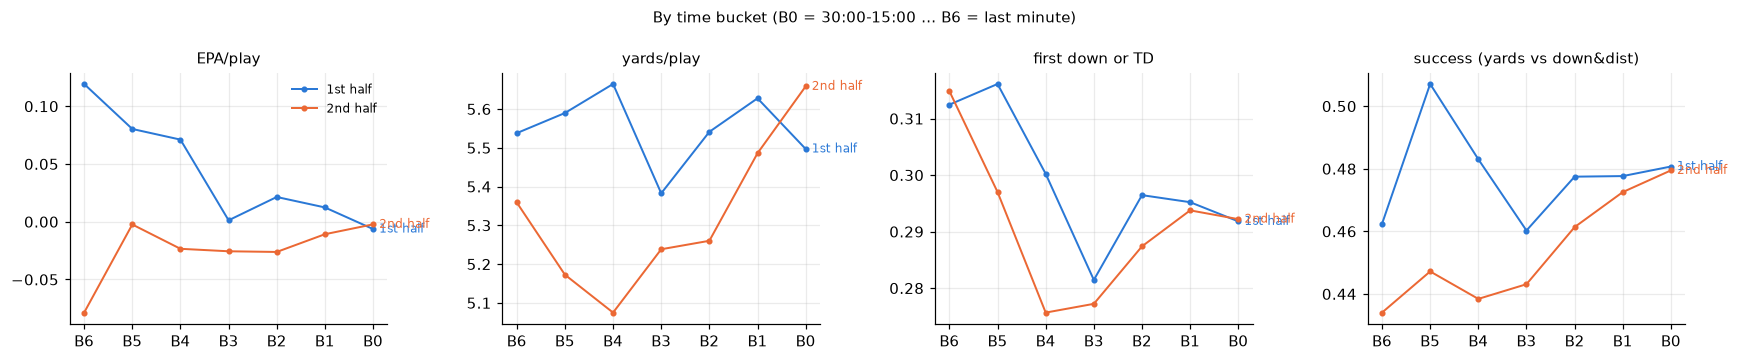

In [5]:
def by_bucket(metric, d=None):
    t = (p if d is None else d).groupby(["bucket", "is_h1"])[metric].mean().unstack("is_h1")
    return t.rename(columns={True: "1st half", False: "2nd half"})

def two_lines(ax, t, title, legend=False):
    for col, colour in [("1st half", BLUE), ("2nd half", ORANGE)]:
        if col in t:
            ax.plot(t.index.astype(str), t[col], color=colour, marker="o", ms=3, label=col)
            ax.annotate(col, (len(t) - 1, t[col].iloc[-1]), xytext=(4, 0), textcoords="offset points",
                        color=colour, fontsize=8, va="center")
    ax.set_title(title, fontsize=10)
    if legend:
        ax.legend(frameon=False, fontsize=8)

fig, axs = plt.subplots(1, 4, figsize=(16, 3.3))
for i, (ax, (m, lab)) in enumerate(zip(axs, METRICS[:4])):
    two_lines(ax, by_bucket(m), lab, legend=i == 0)
fig.suptitle("By time bucket (B0 = 30:00-15:00 ... B6 = last minute)", fontsize=10)
plt.tight_layout(); plt.show()

**Reading.** The surge mostly doesn't show up outside EPA. Late minus rest, 1st half: yards/play +0.01 [−0.08, +0.11], raw success +0.001 [−0.006, +0.008], first-down-or-TD rate +1.4 points [+0.9, +1.9]. Explosive plays −0.9 pts, turnovers +0.6 pts, sacks +1.3 pts, all *worse* late. Pre-spec verdict: **partly artifact** (first-down rate passes, yards and success fail). The first-down bump isn't 1st-half specific: the bucket chart shows it rising in the last 2-3 minutes of *both* halves. 2nd half: raw yards (−0.35) and success (−3.3 pts) drop late, in line with the EPA dip.

This result prompted Step 1b (added after seeing it, logged as doc v1.6), which tests why EPA rises when raw outcomes don't.

## Step 1b · Why does EPA rise when the football doesn't? (added after Step 1, doc v1.6)
Diagnostic, not a new outcome. We compare plays with the **same result**: same down x distance, same field position, same outcome (a 4-6 yd gain, an incompletion, a sack, a turnover...; "+FD" = gained a first down). The EPA gap then splits into:
- **what happened**: late plays have a better or worse mix of outcomes, valued at rest-of-half prices (this is a clock-neutral EPA), and
- **how EPA prices them**: the same result is worth more or less late.

In [6]:
yb = pd.cut(h1["yds"], [-99, 0, 3, 6, 9, 19, 99], labels=["<=0", "1-3", "4-6", "7-9", "10-19", "20+"]).astype(str)
h1 = h1.assign(outc=np.select([h1["turnover"] == 1, h1["sack"] == 1, h1["incomplete_pass"].fillna(0) == 1],
                              ["turnover", "sack", "incomplete"], default="gain " + yb) + np.where(h1["fd"] == 1, " +FD", ""))
val = gap(h1, "epa", cells=["dd", "fp", "outc"])
print("1st-half EPA gap", ci(val))
print("  part from WHAT HAPPENED (outcome mix, valued at rest-of-half prices):", ci(val, "mix"), "| share", pct(val))
print("  part from HOW EPA PRICES the same result late (within):", ci(val, "within"))
tab = h1.groupby(["outc", "late"])["epa"].agg(["mean", "size"]).unstack("late")
tab.columns = [f"{a} {'late' if b else 'rest'}" for a, b in tab.columns]
tab["late - rest"] = tab["mean late"] - tab["mean rest"]
log_r("Step 1b", "outcome mix share of EPA gap (real football part)", val)
display(tab[["mean rest", "mean late", "late - rest", "size late"]].round(3).sort_values("mean rest"))

1st-half EPA gap +0.079 [+0.066, +0.094]
  part from WHAT HAPPENED (outcome mix, valued at rest-of-half prices): -0.018 [-0.031, -0.002] | share -23% [-47, -2]
  part from HOW EPA PRICES the same result late (within): +0.096 [+0.090, +0.102]


,mean rest,mean late,late - rest,size late
outc,,,,
turnover +FD,-6.914,-7.449,-0.535,65.0
turnover,-3.825,-3.077,0.748,703.0
sack,-1.368,-0.891,0.476,1448.0
gain <=0,-0.848,-0.699,0.150,1960.0
incomplete,-0.781,-0.452,0.328,7890.0
gain 1-3,-0.377,-0.267,0.110,3635.0
gain 4-6,-0.025,0.013,0.039,3946.0
gain 7-9,0.348,0.271,-0.077,2912.0
gain 10-19,0.415,0.375,-0.040,499.0


**Reading.** This settles Step 1. Of the +0.079 gap, **how EPA prices the same result accounts for +0.096 [+0.090, +0.102]**. What actually happened is **−0.018 [−0.031, −0.002]**, slightly *worse* football late.

The table shows the mechanism: late in the 1st half, EPA squeezes every outcome toward zero. Bad plays cost less (incompletion −0.78 → −0.45, sack −1.37 → −0.89, turnover −3.83 → −3.08) and good plays are worth less (10-19 yd first down 1.13 → 0.97, 20+ yd play 2.18 → 2.04). The floor rises more than the ceiling falls, and incompletions are the most common late outcome, so average EPA goes up.

This isn't EPA being wrong: with little time left, a failed play really does cost fewer expected points, because the opponent can't use the field position. EPA measures **value**, which does rise late. **Performance** doesn't. The "surge" is a valuation effect, which is consistent with Phase 1's finding of no per-drive surge.

## Step 2 · H8 Composition: is it just *who* has the ball late?
If better offenses (or teams facing weak defenses) run more of the late 1st-half plays, the surge is a mix effect and there's nothing to "apply" elsewhere. Two checks (§ H8):
1. **Team-quality mix.** Each team-season gets an offense rating (EPA/play) and each opponent a defense rating (EPA/play allowed), both built *without* 1st-half late plays so the outcome can't leak in. If late plays come from better offenses by +x, that alone predicts a gap of about +x. Same for defenses.
2. **Same team, same game.** Compare each team's late plays with *its own* earlier plays in the same half (fixed effects). Anything about the team, opponent, weather or game is held constant.

In [7]:
excl = ~(p["is_h1"] & p["late"])
p = p.join(p[excl].groupby(["season", "posteam"])["epa"].mean().rename("off_q"), on=["season", "posteam"])
p = p.join(p[excl].groupby(["season", "defteam"])["epa"].mean().rename("def_q"), on=["season", "defteam"])
h1, h2 = p[p["is_h1"]], p[~p["is_h1"]]

comp = gaps(h1, ["epa", "off_q", "def_q", "home"],
            combos={"predicted by team mix": lambda g: g["off_q"] + g["def_q"],
                    "share": lambda g: (g["off_q"] + g["def_q"]) / g["epa"]})
display(comp.round(4))

raw_o, fe_o = ols_late(h1), ols_late(h1, fe=["game_id", "posteam", "game_half"])
fe_share = 1 - fe_o["draws"] / raw_o["draws"]
print(f"raw gap {ci(raw_o)} | same team-game gap {ci(fe_o)} | share explained "
      f"{(1 - fe_o['est'] / raw_o['est']) * 100:.0f}% [{np.percentile(fe_share, 2.5) * 100:.0f}, {np.percentile(fe_share, 97.5) * 100:.0f}]")

log_r("H8", "team-quality mix share", comp)
log("H8", "same team-game (fixed effects) share", 1 - fe_o["est"] / raw_o["est"], *np.percentile(fe_share, [2.5, 97.5]))

,est,lo,hi
epa,0.0786,0.0658,0.0935
off_q,0.0001,-0.0010,0.0012
def_q,0.0001,-0.0007,0.0009
home,0.0021,-0.0066,0.0112
predicted by team mix,0.0003,-0.0013,0.0016
share,0.0033,-0.0170,0.0215


raw gap +0.079 [+0.066, +0.094] | same team-game gap +0.079 [+0.065, +0.094] | share explained -0% [-5, 4]


**Reading.** Composition is **ruled out**. Late plays come from the same teams (offense quality gap +0.0001, defense +0.0001, predicted share 0% [−2, 2]). The gap within the same team, same game and half is +0.079, identical to the raw gap (0% explained [−5, 4]).

## Step 3 · H1 No-huddle and pace
The original theory. Three questions, in order:
1. Do teams actually go no-huddle / faster late? (If not, the theory dies immediately.)
2. How much of the gap is just *more no-huddle plays late* (mix share), and is there still a surge on huddle plays?
3. Are no-huddle / fast-tempo plays better like-for-like (same down, distance, score state)?

**Tempo measure.** Game-clock seconds from the previous snap to this one, same drive, but only on *clean* intervals: previous play completed in bounds, no penalty, no timeout used by either team, not across the 2:00 warning, 8 to 45 s. Otherwise clock stoppages make late tempo look artificially fast. Fast / mid / slow = terciles of clean 1st-half rest-of-half intervals.

clean tempo intervals: 47.4% of plays; tercile cut-offs 36 s / 40 s


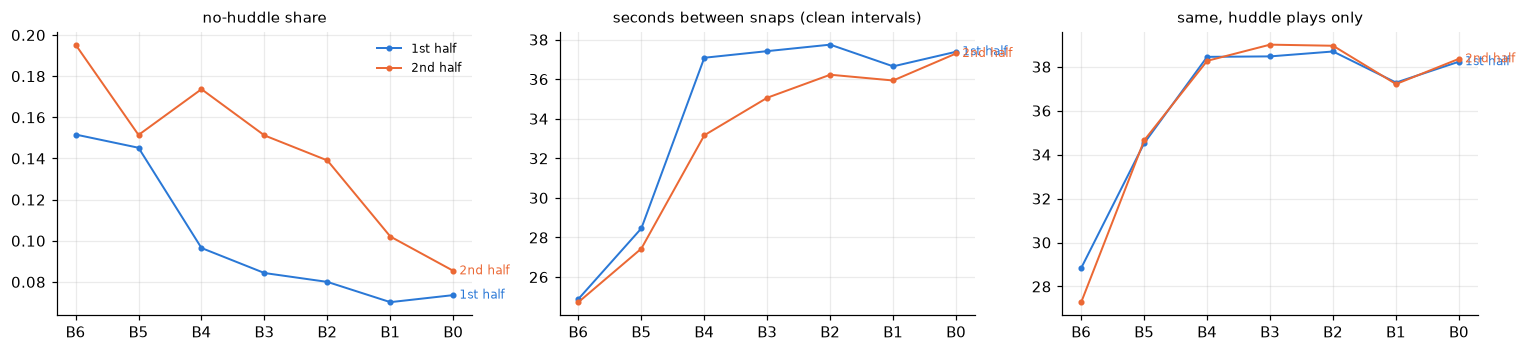

In [8]:
p = p.sort_values(["game_id", "play_id"]).reset_index(drop=True)
g = p.groupby(["game_id", "fixed_drive"], sort=False)
prev = lambda c: g[c].shift()

if "out_of_bounds" in p:
    p["oob"] = p["out_of_bounds"].fillna(0).astype(int)
else:   # fallback: play description
    p["oob"] = p["desc"].fillna("").str.contains(r"out of bounds|\bran ob\b|\bpushed ob\b", case=False).astype(int)

elapsed = prev("game_seconds_remaining") - p["game_seconds_remaining"]
stopped = (prev("incomplete_pass").fillna(0).eq(1) | prev("penalty").fillna(0).eq(1) | prev("oob").fillna(0).eq(1))
to_used = (prev("posteam_timeouts_remaining") != p["posteam_timeouts_remaining"]) | \
          (prev("defteam_timeouts_remaining") != p["defteam_timeouts_remaining"])
warn = (prev("half_seconds_remaining") > 120) & (p["half_seconds_remaining"] <= 120)
clean = elapsed.between(8, 45) & ~stopped & ~to_used & ~warn & prev("game_half").eq(p["game_half"])
p["tempo"] = elapsed.where(clean)
q = p.loc[p["is_h1"] & ~p["late"], "tempo"].quantile([1 / 3, 2 / 3])
p["tbin"] = pd.cut(p["tempo"], [0, q.iloc[0], q.iloc[1], 99], labels=["fast", "mid", "slow"]).astype(object)
h1, h2 = p[p["is_h1"]], p[~p["is_h1"]]
print(f"clean tempo intervals: {p['tempo'].notna().mean():.1%} of plays; tercile cut-offs {q.iloc[0]:.0f} s / {q.iloc[1]:.0f} s")

fig, axs = plt.subplots(1, 3, figsize=(14, 3.3))
two_lines(axs[0], by_bucket("nh"), "no-huddle share", legend=True)
two_lines(axs[1], by_bucket("tempo"), "seconds between snaps (clean intervals)")
two_lines(axs[2], by_bucket("tempo", p[p["nh"] == 0]), "same, huddle plays only")
plt.tight_layout(); plt.show()

In [9]:
rows = {}
for lab, d, m in [("no-huddle share", h1, "nh"), ("sec between snaps (all)", h1, "tempo"),
                  ("sec between snaps (huddle)", h1[h1["nh"] == 0], "tempo"),
                  ("sec between snaps (no-huddle)", h1[h1["nh"] == 1], "tempo")]:
    r = gap(d, m)
    rows[lab] = {"late": round(r.loc["g1", "est"], 3), "rest": round(r.loc["g0", "est"], 3), "gap [95%]": ci(r)}
print("1st half: does tempo change late?"); display(pd.DataFrame(rows).T)

nh_dec = gap(h1, "epa", cells="nh")
hud, nho = gap(h1[h1["nh"] == 0], "epa"), gap(h1[h1["nh"] == 1], "epa")
print("EPA gap split by no-huddle  | total", ci(nh_dec), "| mix", ci(nh_dec, "mix"), "| share", pct(nh_dec))
print("surge on huddle plays only  |", ci(hud), f"({hud.loc['total', 'est'] / base1.loc['total', 'est']:.0%} of the full gap)")
print("surge on no-huddle plays    |", ci(nho))
log_r("H1", "no-huddle mix share", nh_dec)
log_r("H1", "surge on huddle-only plays (EPA)", hud, "total", kind="gap")

1st half: does tempo change late?


,late,rest,gap [95%]
no-huddle share,0.131,0.074,"+0.058 [+0.053, +0.062]"
sec between snaps (all),31.852,37.239,"-5.387 [-5.586, -5.190]"
sec between snaps (huddle),36.273,38.036,"-1.762 [-1.967, -1.561]"
sec between snaps (no-huddle),24.286,30.759,"-6.473 [-6.750, -6.168]"


EPA gap split by no-huddle  | total +0.079 [+0.066, +0.094] | mix +0.001 [-0.000, +0.002] | share 1% [-0, 3]
surge on huddle plays only  | +0.075 [+0.061, +0.091] (95% of the full gap)
surge on no-huddle plays    | +0.098 [+0.063, +0.137]


In [10]:
cells = ["dd", "state"]
rows = {}
for lab, d in [("late window", h1[h1["late"]]), ("rest of half", h1[~h1["late"]])]:
    r = gap(d, "epa", flag="nh", cells=cells)
    rows[f"no-huddle vs huddle, {lab}"] = {"raw": ci(r), "like-for-like": ci(r, "within")}
    s = d.dropna(subset=["tbin"])
    s = s[s["tbin"].isin(["fast", "slow"])].assign(fast=lambda x: x["tbin"].eq("fast"))
    r2 = gap(s, "epa", flag="fast", cells=cells)
    rows[f"fast vs slow tempo, {lab}"] = {"raw": ci(r2), "like-for-like": ci(r2, "within")}
display(pd.DataFrame(rows).T)

tb_dec = gap(h1.dropna(subset=["tbin"]), "epa", cells="tbin")
print("EPA gap split by tempo tercile (clean intervals only) | total", ci(tb_dec), "| share", pct(tb_dec))
log_r("H1", "tempo-tercile mix share", tb_dec)

,raw,like-for-like
"no-huddle vs huddle, late window","+0.039 [+0.009, +0.071]","+0.031 [-0.000, +0.065]"
"fast vs slow tempo, late window","+0.041 [-0.012, +0.099]","+0.012 [-0.045, +0.075]"
"no-huddle vs huddle, rest of half","+0.016 [-0.005, +0.037]","+0.004 [-0.016, +0.026]"
"fast vs slow tempo, rest of half","+0.024 [+0.003, +0.045]","+0.004 [-0.017, +0.023]"


EPA gap split by tempo tercile (clean intervals only) | total +0.068 [+0.045, +0.093] | share 3% [-3, 9]


**Reading.** The pace theory is **ruled out**. Snaps do come faster late (−5.4 s between snaps), but mostly because no-huddle plays get much faster (−6.5 s); huddle tempo only speeds up 1.8 s. No-huddle share only goes from 7.4% to 13.1%. The no-huddle mix explains 1% [0, 3] of the gap, and the surge on huddle-only plays is +0.075, 95% of the full gap. Tempo terciles explain 3% [−3, 9].

Like-for-like, no-huddle is borderline better *late* (+0.031 [−0.000, +0.065]) but not in the rest of the half (+0.004), and fast vs slow tempo is ~0 in both. So there's no sign of a pace lever teams could use earlier.

## Step 4 · H7 Game state
Late in the 1st half, trailing teams may push and leading teams may still attack (no reason to run clock with a half to play). In the 2nd half, leaders run clock, trailers gamble. That's the leading candidate for the 2nd-half dip and the small trailing-team lead from Phase 2. Tests: is the late mix of states different (mix share), and is the surge there in *every* state?

state,lead 1-8,lead 9+,tied,trail 1-8,trail 9+
"2nd half, rest",0.210,0.211,0.057,0.223,0.299
"2nd half, late",0.152,0.129,0.067,0.326,0.326
"1st half, rest",0.197,0.050,0.373,0.285,0.094
"1st half, late",0.244,0.158,0.092,0.282,0.223


1st half: mix share by score state 6% [0, 13] | like-for-like gap +0.074 [+0.060, +0.090]
2nd half: mix share by score state 11% [-1, 53] | like-for-like gap -0.017 [-0.033, -0.001]  (share is noisy when the total is near 0)


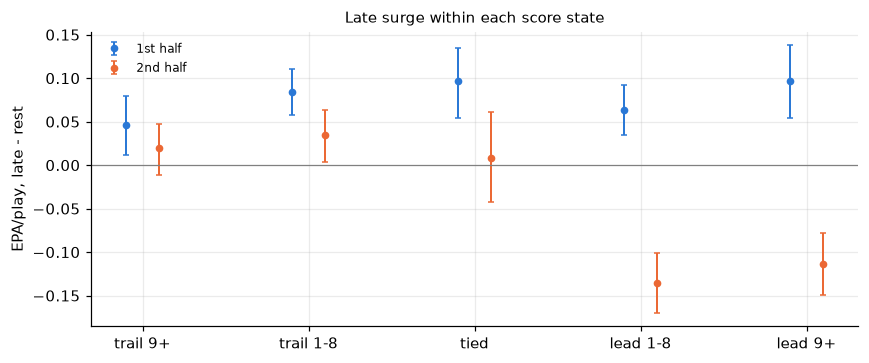

In [11]:
shares = (p.groupby(["is_h1", "late"])["state"].value_counts(normalize=True).unstack("state").round(3))
shares.index = [f"{'1st' if a else '2nd'} half, {'late' if b else 'rest'}" for a, b in shares.index]
display(shares)

st1, st2 = gap(h1, "epa", cells="state"), gap(h2, "epa", cells="state")
print("1st half: mix share by score state", pct(st1), "| like-for-like gap", ci(st1, "within"))
print("2nd half: mix share by score state", pct(st2), "| like-for-like gap", ci(st2, "within"),
      " (share is noisy when the total is near 0)")
log_r("H7", "score-state mix share (1st half)", st1)

STATES = ["trail 9+", "trail 1-8", "tied", "lead 1-8", "lead 9+"]
res = {(h, s): gap(d[d["state"] == s], "epa") for h, d in [("1st", h1), ("2nd", h2)] for s in STATES}
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(STATES))
for j, (h, col) in enumerate([("1st", BLUE), ("2nd", ORANGE)]):
    e = np.array([res[(h, s)].loc["total", "est"] for s in STATES])
    lo = np.array([res[(h, s)].loc["total", "lo"] for s in STATES])
    hi = np.array([res[(h, s)].loc["total", "hi"] for s in STATES])
    ax.errorbar(x + (j - .5) * .2, e, yerr=[e - lo, hi - e], fmt="o", color=col, ms=4, capsize=2, label=f"{h} half")
ax.axhline(0, color="grey", lw=.8)
ax.set_xticks(x, STATES); ax.set_ylabel("EPA/play, late - rest"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Late surge within each score state", fontsize=10)
plt.tight_layout(); plt.show()

In [12]:
h2s = h2.assign(side=np.select([h2["score_differential"] < 0, h2["score_differential"] > 0], ["trailing", "leading"], "tied"))
tab = {}
for s in sorted(h2s["season"].unique()):
    for side in ["trailing", "leading"]:
        tab.setdefault(s, {})[side] = ci(gap(h2s[(h2s["season"] == s) & (h2s["side"] == side)], "epa", nboot=300), nd=2)
print("2nd half, late - rest EPA/play by season (300 draws each)")
display(pd.DataFrame(tab).T)

2nd half, late - rest EPA/play by season (300 draws each)


,trailing,leading
2016,"+0.01 [-0.05, +0.08]","-0.14 [-0.22, -0.06]"
2017,"+0.01 [-0.05, +0.08]","-0.13 [-0.22, -0.05]"
2018,"+0.04 [-0.03, +0.11]","-0.10 [-0.17, -0.02]"
2019,"+0.05 [-0.02, +0.11]","-0.14 [-0.22, -0.07]"
2020,"+0.04 [-0.03, +0.10]","-0.10 [-0.19, -0.03]"
2021,"+0.03 [-0.03, +0.09]","-0.12 [-0.21, -0.05]"
2022,"+0.01 [-0.07, +0.09]","-0.14 [-0.21, -0.07]"
2023,"-0.05 [-0.12, +0.00]","-0.15 [-0.22, -0.09]"
2024,"+0.09 [+0.03, +0.14]","-0.06 [-0.14, +0.01]"
2025,"+0.07 [+0.01, +0.14]","-0.15 [-0.24, -0.07]"


**Reading.** 1st half: score state explains 6% [0, 13] (**ruled out**). The like-for-like gap stays +0.074 and the surge appears in every state.

2nd half: the dip comes from leaders. In every season, leading teams' late EPA drops 0.06 to 0.15 (9 of 10 seasons clearly below 0), while trailing teams sit near 0 to slightly positive. The 2024-25 "flip" is trailing teams doing better (+0.09, +0.07) and, in 2024, leaders dropping less (−0.06). Phase 4 should check whether this is real football or valuation too (Step 1b on the 2nd half).

## Step 5 · Extra data: participation and FTN charting
H2, H5 and H6 need things pbp doesn't have: defensive personnel (DB count), pass rushers, coverage, offensive personnel, which defenders were on the field. nflverse has two sources: **participation** (`load_participation`) and **FTN charting** (`load_ftn_charting`, 2022+). We load season by season, cache to `../data/`, and print coverage before deciding what's testable (§ fixed rules: no field, no test).

In [13]:
SEASONS = sorted(int(s) for s in p["season"].unique())

def load_extra(name, loader, seasons):
    path = DATA / f"{name}.parquet"
    if path.exists():
        return pd.read_parquet(path)
    try:
        import nflreadpy as nfl
    except ImportError:
        print("nflreadpy not importable"); return None
    frames = []
    for s in seasons:
        try:
            frames.append(getattr(nfl, loader)([s]).to_pandas())
        except Exception as e:
            print(f"  {name} {s}: skipped ({type(e).__name__})")
    if not frames:
        return None
    df = pd.concat(frames, ignore_index=True)
    df.to_parquet(path)
    return df

part = load_extra("participation", "load_participation", SEASONS)
ftn = load_extra("ftn", "load_ftn_charting", [s for s in SEASONS if s >= 2022])
for name, df in [("participation", part), ("ftn", ftn)]:
    print(name, None if df is None else df.shape)
    if df is not None:
        print("  columns:", ", ".join(df.columns[:40]))

participation (478989, 26)
  columns: nflverse_game_id, old_game_id, play_id, possession_team, offense_formation, offense_personnel, defenders_in_box, defense_personnel, number_of_pass_rushers, players_on_play, offense_players, defense_players, n_offense, n_defense, ngs_air_yards, time_to_throw, was_pressure, route, defense_man_zone_type, defense_coverage_type, offense_names, defense_names, offense_positions, defense_positions, offense_numbers, defense_numbers
ftn (185215, 29)
  columns: ftn_game_id, nflverse_game_id, season, week, ftn_play_id, nflverse_play_id, starting_hash, qb_location, n_offense_backfield, n_defense_box, is_no_huddle, is_motion, is_play_action, is_screen_pass, is_rpo, is_trick_play, is_qb_out_of_pocket, is_interception_worthy, is_throw_away, read_thrown, is_catchable_ball, is_contested_ball, is_created_reception, is_drop, is_qb_sneak, n_blitzers, n_pass_rushers, is_qb_fault_sack, date_pulled


In [14]:
P_COLS = ["offense_formation", "offense_personnel", "defense_personnel", "defenders_in_box",
          "number_of_pass_rushers", "defense_coverage_type", "defense_man_zone_type", "defense_players"]
F_COLS = ["is_play_action", "is_screen_pass", "is_motion", "is_rpo", "n_blitzers"]

if part is not None:
    pp = part.rename(columns={"nflverse_game_id": "game_id"})
    keep = [c for c in P_COLS if c in pp]
    p = p.merge(pp[["game_id", "play_id"] + keep].drop_duplicates(["game_id", "play_id"]), on=["game_id", "play_id"], how="left")
if ftn is not None:
    ff = ftn.rename(columns={"nflverse_game_id": "game_id", "nflverse_play_id": "play_id"})
    keep = [c for c in F_COLS if c in ff]
    ff = ff[["game_id", "play_id"] + keep].drop_duplicates(["game_id", "play_id"])
    ff[keep] = ff[keep].astype(float)
    p = p.merge(ff, on=["game_id", "play_id"], how="left")

have = [c for c in P_COLS + F_COLS if c in p]
if have:
    print("share of plays with each field, by season")
    display(p.groupby("season")[have].agg(lambda s: s.notna().mean()).round(2))
HAVE_PART = all(c in p for c in ["offense_personnel", "defense_personnel", "number_of_pass_rushers"])
HAVE_SUBS = "defense_players" in p
HAVE_FTN = "is_play_action" in p
print("HAVE_PART", HAVE_PART, "| HAVE_SUBS", HAVE_SUBS, "| HAVE_FTN", HAVE_FTN)

share of plays with each field, by season


,offense_formation,offense_personnel,defense_personnel,defenders_in_box,number_of_pass_rushers,defense_coverage_type,defense_man_zone_type,defense_players,is_play_action,is_screen_pass,is_motion,is_rpo,n_blitzers
season,,,,,,,,,,,,,
2016,0.99,1.0,1.0,1.0,0.60,0.00,0.00,1.0,0.0,0.0,0.0,0.0,0.0
2017,0.99,1.0,1.0,1.0,0.58,0.00,0.00,1.0,0.0,0.0,0.0,0.0,0.0
2018,0.99,1.0,1.0,1.0,0.62,0.55,0.55,1.0,0.0,0.0,0.0,0.0,0.0
2019,1.00,1.0,1.0,1.0,0.62,0.55,0.55,1.0,0.0,0.0,0.0,0.0,0.0
2020,1.00,1.0,1.0,1.0,0.62,0.55,0.55,1.0,0.0,0.0,0.0,0.0,0.0
2021,0.99,1.0,1.0,1.0,0.61,0.55,0.55,1.0,0.0,0.0,0.0,0.0,0.0
2022,1.00,1.0,1.0,1.0,0.60,0.53,0.53,1.0,1.0,1.0,1.0,1.0,1.0
2023,1.00,1.0,1.0,1.0,0.98,0.61,1.00,1.0,1.0,1.0,1.0,1.0,1.0
2024,1.00,1.0,1.0,1.0,1.00,0.60,1.00,1.0,1.0,1.0,1.0,1.0,1.0


HAVE_PART True | HAVE_SUBS True | HAVE_FTN True


In [15]:
def count(s, pos):
    n = pd.to_numeric(s.str.extract(rf"(\d+)\s*{pos}")[0], errors="coerce")
    return n.fillna(0).where(s.notna())

if HAVE_PART:
    op, dp = p["offense_personnel"], p["defense_personnel"]
    rb, te, wr = count(op, "RB"), count(op, "TE"), count(op, "WR")
    pers = (rb.astype("Int64").astype(str) + te.astype("Int64").astype(str)).where(op.notna())
    top = pers.dropna().value_counts().index[:5]
    p["pers"] = pers.where(pers.isin(top), "other").where(pers.notna()).astype(object)
    p["wrcat"] = pd.cut(wr, [-1, 2, 3, 9], labels=["0-2 WR", "3 WR", "4+ WR"]).astype(object)
    p["dbs"] = count(dp, "DB")
    p["dbcat"] = pd.cut(p["dbs"], [-1, 4, 5, 99], labels=["base <=4 DB", "nickel 5", "dime+ 6+"]).astype(object)
    p["rush_n"] = pd.to_numeric(p["number_of_pass_rushers"], errors="coerce")
    p["rcat"] = pd.cut(p["rush_n"], [-1, 3, 4, 99], labels=["<=3 rush", "4 rush", "5+ rush"]).astype(object)
    p["soft"] = ((p["dbs"] >= 6) | (p["rush_n"] <= 3)).astype(float).where(p["dbs"].notna() & p["rush_n"].notna())
    if "defense_coverage_type" in p:
        p["cover"] = p["defense_coverage_type"].astype(object)
    if "defense_man_zone_type" in p:
        p["manzone"] = p["defense_man_zone_type"].astype(object)
    print("personnel groups (RB+TE digits):", list(top), "+ other")

if HAVE_SUBS:   # defenders on this snap who weren't on the previous snap of the same drive
    sets = [frozenset(s.split(";")) if isinstance(s, str) and s else None for s in p["defense_players"]]
    same = ((p["game_id"] == p["game_id"].shift()) & (p["fixed_drive"] == p["fixed_drive"].shift())).to_numpy()
    subs = np.full(len(p), np.nan)
    for i in range(1, len(p)):
        if same[i] and sets[i] is not None and sets[i - 1] is not None:
            subs[i] = len(sets[i] - sets[i - 1])
    p["d_subs"] = subs
    p["any_sub"] = (p["d_subs"] > 0).astype(float).where(p["d_subs"].notna())
    print(f"defensive sub info on {np.isfinite(subs).mean():.1%} of plays; mean subs {np.nanmean(subs):.2f}")

h1, h2 = p[p["is_h1"]], p[~p["is_h1"]]

personnel groups (RB+TE digits): ['11', '12', '21', '13', '22'] + other
defensive sub info on 82.8% of plays; mean subs 1.30


**Reading.** Participation covers 2016-2025 for personnel, box count and defensive player IDs (100%). Pass rushers: ~60% of plays to 2022, ~100% from 2023. Coverage type: 2018+, ~55-60%. Man/zone: 2018+, 100% from 2023. FTN charting: 2022-2025. So H2, H5 and H6 run on nearly all seasons; coverage-type results come from 2018+ only.

## Step 6 · H2 Prevent / soft coverage
If defenses sit back late in the 1st half (more DBs, fewer rushers, deep zone), offenses get easy underneath yards. Signature even without charting: completion % up, air yards down, sacks down. With participation we test the shell directly, and the strongest check: **is there still a surge on plays where the defense was *not* soft** (≤ 5 DBs and ≥ 4 rushers)?

In [16]:
pa = h1[h1["is_pass"] == 1].copy()
pa["att"] = 1 - pa["sack"]
pa["comp"] = pa["complete_pass"].fillna(0).where(pa["att"] == 1)
pa["air"] = pa["air_yards"].where(pa["att"] == 1)
pa["short"] = (pa["air"] <= 5).astype(float).where(pa["air"].notna())
rows = {}
for m, lab in [("epa", "EPA/dropback"), ("yds", "yards/dropback"), ("comp", "completion %"),
               ("air", "air yards/attempt"), ("short", "share of throws <= 5 air yds"), ("sack", "sack rate")]:
    r = gap(pa, m)
    rows[lab] = {"late": round(r.loc["g1", "est"], 3), "rest": round(r.loc["g0", "est"], 3), "gap [95%]": ci(r)}
print("1st-half dropbacks (pbp only, indirect)"); display(pd.DataFrame(rows).T)

1st-half dropbacks (pbp only, indirect)


,late,rest,gap [95%]
EPA/dropback,0.101,0.046,"+0.054 [+0.036, +0.072]"
yards/dropback,5.928,6.461,"-0.533 [-0.659, -0.395]"
completion %,0.599,0.629,"-0.030 [-0.037, -0.023]"
air yards/attempt,8.257,7.566,"+0.691 [+0.535, +0.839]"
share of throws <= 5 air yds,0.496,0.532,"-0.036 [-0.044, -0.029]"
sack rate,0.062,0.06,"+0.003 [-0.001, +0.006]"


,late,rest,gap [95%]
DBs on field,3.648,3.412,"+0.236 [+0.198, +0.268]"
pass rushers,4.162,4.258,"-0.096 [-0.107, -0.083]"
soft shell share,0.267,0.18,"+0.086 [+0.078, +0.095]"


pass-play EPA gap (participation seasons): +0.055 [+0.037, +0.074] | shell mix share -22% [-35, -12]
coverage type mix share -17% [-31, -10] (n = 75,070)
man/zone mix share 1% [-1, 3] (n = 75,143)
surge on NON-soft plays: +0.049 [+0.029, +0.070] | on soft plays: +0.078 [+0.042, +0.114]


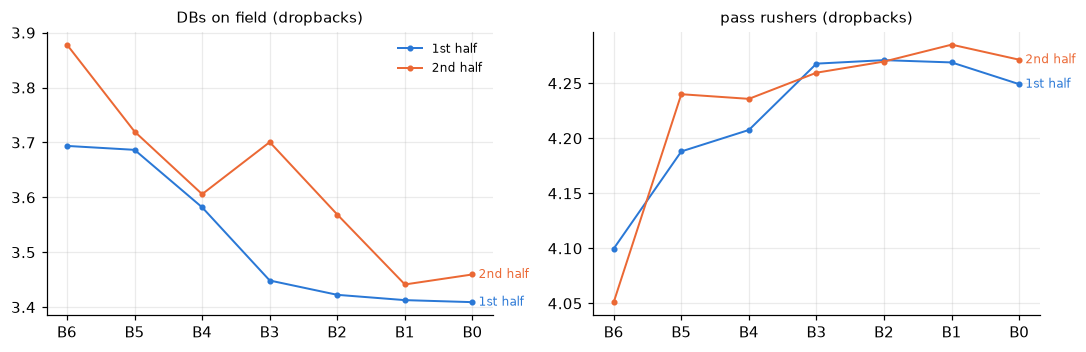

In [17]:
if HAVE_PART:
    rows = {}
    for m, lab in [("dbs", "DBs on field"), ("rush_n", "pass rushers"), ("soft", "soft shell share")]:
        r = gap(pa, m)
        rows[lab] = {"late": round(r.loc["g1", "est"], 3), "rest": round(r.loc["g0", "est"], 3), "gap [95%]": ci(r)}
    display(pd.DataFrame(rows).T)

    shell = gap(pa, "epa", cells=["dbcat", "rcat"])
    print("pass-play EPA gap (participation seasons):", ci(shell), "| shell mix share", pct(shell))
    log_r("H2", "defensive shell mix share (pass plays)", shell)
    for col, lab in [("cover", "coverage type"), ("manzone", "man/zone")]:
        if col in pa and pa[col].notna().mean() > .2:
            r = gap(pa, "epa", cells=col)
            print(f"{lab} mix share", pct(r), f"(n = {pa[col].notna().sum():,})")
            log_r("H2", f"{lab} mix share (pass plays)", r)
    ns, sf = gap(pa[pa["soft"] == 0], "epa"), gap(pa[pa["soft"] == 1], "epa")
    print("surge on NON-soft plays:", ci(ns), "| on soft plays:", ci(sf))
    log_r("H2", "surge on non-soft pass plays (EPA)", ns, "total", kind="gap")

    fig, axs = plt.subplots(1, 2, figsize=(10, 3.3))
    two_lines(axs[0], by_bucket("dbs", p[p["is_pass"] == 1]), "DBs on field (dropbacks)", legend=True)
    two_lines(axs[1], by_bucket("rush_n", p[p["is_pass"] == 1]), "pass rushers (dropbacks)")
    plt.tight_layout(); plt.show()
else:
    print("no participation data: H2 shell tests cannot be run (doc v1.5); only the pbp proxies above")
    log("H2", "defensive shell mix share", np.nan, np.nan, np.nan, kind="n/a", note="cannot test")

**Reading.** Soft coverage is **ruled out** as the driver. Defenses do go softer late (DBs +0.24, rushers −0.10, soft-shell share 18% → 27%). But the shell mix share is **−22% [−35, −12]**: plays against soft shells go *worse* for offenses, so more of them should pull EPA down. Coverage type is also negative (−17%), and man/zone is 1%. The surge is still +0.049 on non-soft plays. The pbp signature is also the opposite of prevent: completion % −3.0 pts, air yards +0.7, short-throw share −3.6 pts, yards/dropback −0.53. Offenses throw deeper into softer shells and complete less.

## Step 7 · H5 Personnel and formation
Late offenses go spread: more WRs, more shotgun. If spread looks are just better plays, part of the surge is a personnel mix effect. Shotgun works on every season (pbp); personnel needs participation.

,total gap (these plays),within,mix share
shotgun,"+0.079 [+0.066, +0.094]","+0.081 [+0.067, +0.097]","-3% [-7, -0]"
personnel group,"+0.079 [+0.066, +0.094]","+0.082 [+0.068, +0.098]","-4% [-8, -1]"
WR count,"+0.079 [+0.066, +0.094]","+0.082 [+0.068, +0.098]","-4% [-8, -1]"
personnel x shotgun,"+0.079 [+0.066, +0.094]","+0.085 [+0.071, +0.101]","-8% [-13, -3]"


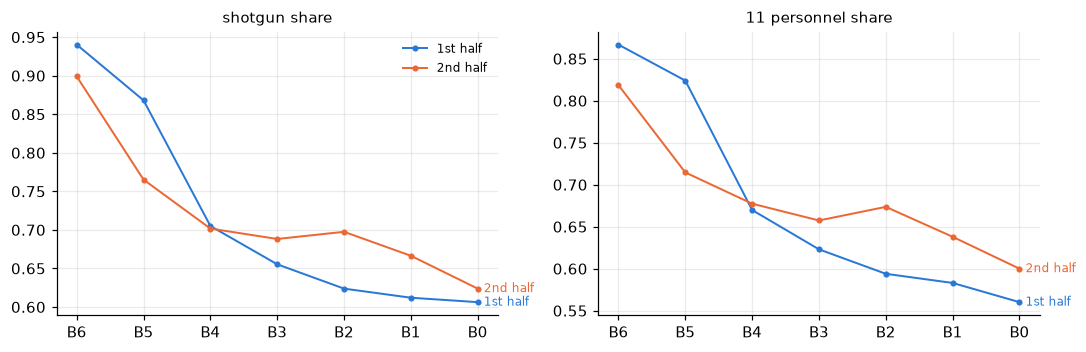

In [18]:
specs = [("shotgun", ["shot"])]
if HAVE_PART:
    specs += [("personnel group", ["pers"]), ("WR count", ["wrcat"]), ("personnel x shotgun", ["pers", "shot"])]
rows = {}
for lab, c in specs:
    r = gap(h1, "epa", cells=c)
    rows[lab] = {"total gap (these plays)": ci(r), "within": ci(r, "within"), "mix share": pct(r)}
display(pd.DataFrame(rows).T)
r5 = gap(h1, "epa", cells=specs[-1][1])
log_r("H5", f"{specs[-1][0]} mix share", r5)

fig, axs = plt.subplots(1, 2 if HAVE_PART else 1, figsize=(10 if HAVE_PART else 5, 3.3), squeeze=False)
two_lines(axs[0, 0], by_bucket("shot"), "shotgun share", legend=True)
if HAVE_PART:
    two_lines(axs[0, 1], by_bucket("is11", p.assign(is11=p["pers"].eq("11").astype(float).where(p["pers"].notna()))), "11 personnel share")
plt.tight_layout(); plt.show()

**Reading.** Personnel/formation is **ruled out** (personnel x shotgun −8% [−13, −3]). Spread looks rise late, but they're slightly *worse* per play than what they replace.

## Step 8 · H3 Play-calling
More passing late is obvious. Passes have higher EPA than runs on average, so "more passes" alone mechanically lifts EPA/play. How much? Then: do the passes themselves change (depth, play action, screens)?

pass share late vs rest: +0.177 [+0.171, +0.182]
EPA gap split by pass/run | mix share 23% [18, 29] | within +0.061 [+0.046, +0.075]
  surge on passes only: +0.054 [+0.036, +0.072] | runs only: +0.080 [+0.061, +0.099]
pass-depth mix share (attempts): 44% [28, 88]


ay_bin,1-5,11-20,20+,6-10,behind LOS
late,,,,,
rest,0.303,0.193,0.097,0.178,0.229
late,0.315,0.197,0.105,0.201,0.181


FTN charting (2022+), rates late vs rest


,late,rest,gap [95%]
is_play_action,0.071,0.16,"-0.089 [-0.094, -0.084]"
is_screen_pass,0.053,0.06,"-0.007 [-0.011, -0.002]"
is_motion,0.385,0.529,"-0.145 [-0.154, -0.134]"
is_rpo,0.044,0.056,"-0.012 [-0.016, -0.008]"


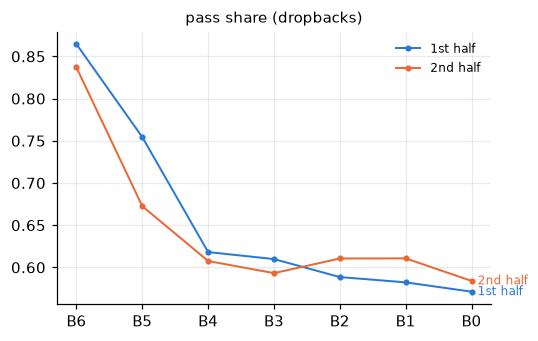

In [19]:
pc = gap(h1, "epa", cells="is_pass")
print("pass share late vs rest:", ci(gap(h1, "is_pass")))
print("EPA gap split by pass/run | mix share", pct(pc), "| within", ci(pc, "within"))
print("  surge on passes only:", ci(gap(h1[h1["is_pass"] == 1], "epa")), "| runs only:", ci(gap(h1[h1["is_pass"] == 0], "epa")))
log_r("H3", "pass/run mix share", pc)

att = h1[(h1["is_pass"] == 1) & h1["air_yards"].notna()].copy()
att["ay_bin"] = pd.cut(att["air_yards"], [-99, 0, 5, 10, 20, 99], labels=["behind LOS", "1-5", "6-10", "11-20", "20+"]).astype(object)
ay = gap(att, "epa", cells="ay_bin")
print("pass-depth mix share (attempts):", pct(ay))
display((att.groupby("late")["ay_bin"].value_counts(normalize=True).unstack().round(3)
         .rename(index={False: "rest", True: "late"})))

if HAVE_FTN:
    rows = {}
    for m in [c for c in F_COLS if c in h1 and c != "n_blitzers"]:
        r = gap(h1, m)
        rows[m] = {"late": round(r.loc["g1", "est"], 3), "rest": round(r.loc["g0", "est"], 3), "gap [95%]": ci(r)}
    print("FTN charting (2022+), rates late vs rest"); display(pd.DataFrame(rows).T)

fig, ax = plt.subplots(figsize=(5, 3.2))
two_lines(ax, by_bucket("is_pass"), "pass share (dropbacks)", legend=True)
plt.tight_layout(); plt.show()

**Reading.** Pass/run mix is the only formal **contributor**: 23% [18, 29]. Passing goes up 17.7 points late. But the surge is bigger on runs (+0.080) than on passes (+0.054), and pass-depth mix (44% [28, 88]) is too noisy to read. Given Step 1b, the most plausible reading is that passing feeds the valuation effect (incompletions get the biggest late discount), not that it produces better plays.

FTN (2022+): offenses get simpler late: play action 16% → 7%, motion 53% → 39%, RPO and screens down slightly.

## Step 9 · H4 Clock, timeouts and the two-minute warning
Two angles. (1) Where exactly does the jump happen? If it sits at the 2:00 warning, a free stoppage is doing something (defense can't sub? offense gets a huddle?). Phase 1 said it starts at B4 (3:00), which already argues against the warning, so we look in 30-second slices. (2) Timeouts are the resource that lets an offense play normally under clock pressure; if they matter, late plays with ≥ 2 timeouts should be better like-for-like than plays with ≤ 1.

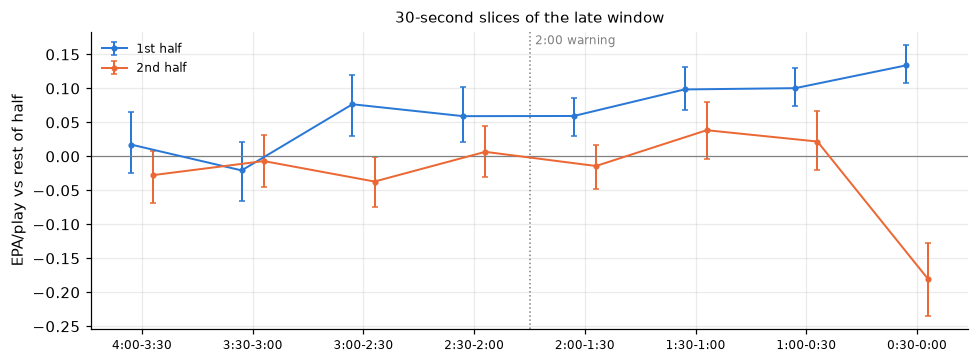

In [20]:
edges = list(range(0, 241, 30))
mmss = lambda s: f"{s // 60}:{s % 60:02d}"
labels = [f"{mmss(hi)}-{mmss(lo)}" for lo, hi in zip(edges[:-1], edges[1:])]
p["sl"] = pd.cut(p["half_seconds_remaining"], edges, labels=labels).astype(object)
h1, h2 = p[p["is_h1"]], p[~p["is_h1"]]

fig, ax = plt.subplots(figsize=(9, 3.4))
order = labels[::-1]
for j, (d, col, name) in enumerate([(h1, BLUE, "1st half"), (h2, ORANGE, "2nd half")]):
    est, lo, hi = [], [], []
    for lab in order:
        r = gap(d[(d["sl"] == lab) | ~d["late"]].assign(f=lambda x: x["sl"].eq(lab)), "epa", flag="f", nboot=500)
        est.append(r.loc["total", "est"]); lo.append(r.loc["total", "lo"]); hi.append(r.loc["total", "hi"])
    est, lo, hi = map(np.array, (est, lo, hi))
    ax.errorbar(np.arange(len(order)) + (j - .5) * .2, est, yerr=[est - lo, hi - est], fmt="o-", ms=3,
                color=col, capsize=2, label=name)
ax.axhline(0, color="grey", lw=.8)
ax.axvline(order.index("2:00-1:30") - .5, color="grey", ls=":", lw=1)
ax.text(order.index("2:00-1:30") - .45, ax.get_ylim()[1] * .9, "2:00 warning", fontsize=8, color="grey")
ax.set_xticks(range(len(order)), order, fontsize=8)
ax.set_ylabel("EPA/play vs rest of half"); ax.legend(frameon=False, fontsize=8)
ax.set_title("30-second slices of the late window", fontsize=10)
plt.tight_layout(); plt.show()

In [21]:
lt = h1[h1["late"]].assign(to_hi=lambda x: x["posteam_timeouts_remaining"] >= 2)
print("share of late 1st-half plays with >= 2 timeouts:", round(lt["to_hi"].mean(), 3))
r4 = gap(lt, "epa", flag="to_hi", cells=["dd", "state"])
print(">= 2 timeouts vs <= 1, late 1st half | raw", ci(r4), "| like-for-like", ci(r4, "within"))
log_r("H4", ">=2 vs <=1 timeouts, like-for-like (late window)", r4, "within", kind="gap",
      note="supported if >= 0.03 with lower bound > 0")

share of late 1st-half plays with >= 2 timeouts: 0.712
>= 2 timeouts vs <= 1, late 1st half | raw -0.046 [-0.071, -0.018] | like-for-like -0.044 [-0.070, -0.014]


**Reading.** The 1st-half line leaves zero in 3:00-2:30 and climbs steadily to +0.13 in the final 30 s. There's no step at the 2:00 warning, so the warning isn't the trigger. A smooth ramp with time left is what a valuation effect predicts. 2nd half: about 0 until the last 30 s, then −0.18.

Timeouts: **not supported, opposite sign**. Late plays with ≥ 2 timeouts are *worse* like-for-like (−0.044 [−0.070, −0.014]). This is observational: teams still holding timeouts may be ones not yet in a hurry.

## Step 10 · H6 Defensive substitution limits
The mechanism people usually mean by "hurry-up works": the defense can't swap personnel, so tired or mismatched players stay on. Two links have to hold (§ H6): (i) defenses actually sub less late, and (ii) plays where the defense didn't sub go better for the offense like-for-like. Only clean-clock intervals are used, so timeouts and stoppages (when anyone can sub) don't blur it.

In [22]:
if HAVE_SUBS:
    sb = h1[h1["tempo"].notna() & h1["any_sub"].notna()].assign(no_sub=lambda x: x["any_sub"].eq(0))
    l1 = gap(sb, "any_sub")
    print("defense subbed before the snap, late vs rest:", ci(l1),
          f"(late {l1.loc['g1', 'est']:.3f}, rest {l1.loc['g0', 'est']:.3f})")
    display(sb.groupby(["tbin", "late"])["any_sub"].mean().unstack().round(3).rename(columns={False: "rest", True: "late"}))
    rows = {}
    for lab, d in [("late window", sb[sb["late"]]), ("rest of half", sb[~sb["late"]])]:
        r = gap(d, "epa", flag="no_sub", cells=["dd", "state"])
        rows[lab] = {"no sub minus sub, raw": ci(r), "like-for-like": ci(r, "within")}
    display(pd.DataFrame(rows).T)
    l2 = gap(sb, "epa", flag="no_sub", cells=["dd", "state"])
    m6 = gap(sb, "epa", cells="any_sub")
    print("EPA gap split by any_sub | mix share", pct(m6))
    log_r("H6", "link (i): any-sub rate late - rest", l1, "total", kind="gap")
    log_r("H6", "link (ii): no-sub minus sub EPA, like-for-like", l2, "within", kind="gap")
    log_r("H6", "any-sub mix share", m6)
else:
    print("no defense_players field: H6 cannot be tested (doc v1.5)")
    log("H6", "defensive subs", np.nan, np.nan, np.nan, kind="n/a", note="cannot test")

defense subbed before the snap, late vs rest: -0.204 [-0.215, -0.194] (late 0.415, rest 0.619)


late,rest,late
tbin,,
fast,0.514,0.273
mid,0.633,0.555
slow,0.716,0.670


,"no sub minus sub, raw",like-for-like
late window,"+0.000 [-0.046, +0.046]","-0.019 [-0.067, +0.030]"
rest of half,"+0.013 [-0.006, +0.031]","-0.007 [-0.025, +0.011]"


EPA gap split by any_sub | mix share 4% [-2, 10]


**Reading.** Link (i) **holds**: defenses sub far less late (62% → 42% of snaps). It's not only tempo: within each tempo third subs drop late, most at fast tempo (51% → 27%). Link (ii) **fails**: plays where the defense didn't sub aren't better, late (−0.019 [−0.067, +0.030]) or in the rest of the half (−0.007). Mix share 4% [−2, 10]. **H6 not supported.** Freezing the defense happens, but it doesn't help the offense.

## Step 11 · Heterogeneity: who gets more of the boost?
Your point from the start of this phase: if *everyone* gets a boost, that's meaningful in itself, and the shape of who gets more tells us why. Different mechanisms predict different patterns:
- soft coverage (H2) → bigger boost for offenses that can punish soft shells (good passing teams), present against every defense
- pace / defensive fatigue (H1/H6) → bigger boost against teams that sub a lot, and for teams that rarely go fast (the change is bigger)
- measurement (Step 1) → roughly the same boost for everyone

Splits by team-season thirds (built without 1st-half late plays, same as H8).

,split,comparison,difference in surge
0,offense quality,strong O - weak O,"+0.005 [-0.028, +0.037]"
1,opposing defense,weak D - strong D,"-0.006 [-0.042, +0.030]"
2,pass lean,pass-heavy - run-leaning,"+0.029 [-0.002, +0.062]"
3,venue,home - away,"+0.023 [-0.005, +0.052]"


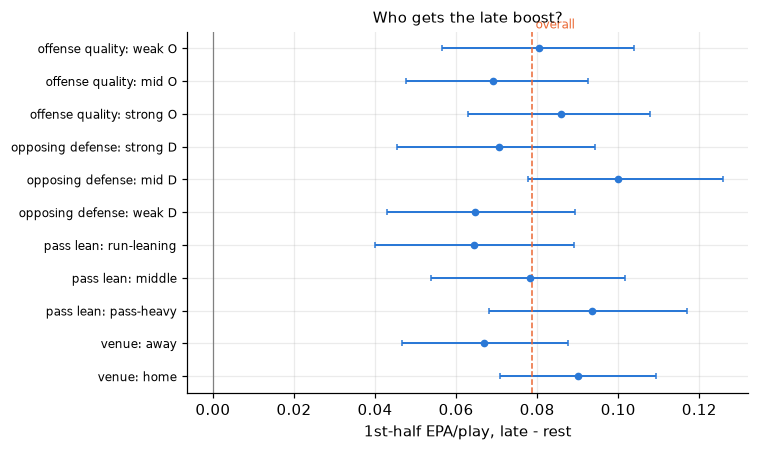

In [23]:
excl = ~(p["is_h1"] & p["late"])
p = p.join(p[excl].groupby(["season", "posteam"])["is_pass"].mean().rename("pass_rate"), on=["season", "posteam"])
p["off_t"] = pd.qcut(p["off_q"], 3, labels=["weak O", "mid O", "strong O"]).astype(object)
p["def_t"] = pd.qcut(p["def_q"], 3, labels=["strong D", "mid D", "weak D"]).astype(object)
p["pr_t"] = pd.qcut(p["pass_rate"], 3, labels=["run-leaning", "middle", "pass-heavy"]).astype(object)
p["ha"] = np.where(p["home"] == 1, "home", "away")
h1, h2 = p[p["is_h1"]], p[~p["is_h1"]]

DIMS = [("offense quality", "off_t", ["weak O", "mid O", "strong O"]),
        ("opposing defense", "def_t", ["strong D", "mid D", "weak D"]),
        ("pass lean", "pr_t", ["run-leaning", "middle", "pass-heavy"]),
        ("venue", "ha", ["away", "home"])]
rows, plot_rows = [], []
for name, col, levels in DIMS:
    for lv in levels:
        r = gap(h1[h1[col] == lv], "epa")
        plot_rows.append((name, lv, *r.loc["total", ["est", "lo", "hi"]]))
    dg = diff_gap(h1, "epa", col, levels[-1], levels[0])
    rows.append({"split": name, f"comparison": f"{levels[-1]} - {levels[0]}", "difference in surge": ci(dg, "diff")})
    log_r("Hetero", f"surge {levels[-1]} - {levels[0]}", dg, "diff", kind="gap")
display(pd.DataFrame(rows))

pr = pd.DataFrame(plot_rows, columns=["dim", "level", "est", "lo", "hi"])
fig, ax = plt.subplots(figsize=(7, 4.2))
y = np.arange(len(pr))[::-1]
ax.errorbar(pr["est"], y, xerr=[pr["est"] - pr["lo"], pr["hi"] - pr["est"]], fmt="o", color=BLUE, ms=4, capsize=2)
ax.axvline(base1.loc["total", "est"], color=ORANGE, lw=1, ls="--")
ax.text(base1.loc["total", "est"], y.max() + .6, " overall", color=ORANGE, fontsize=8)
ax.axvline(0, color="grey", lw=.8)
ax.set_yticks(y, [f"{d}: {l}" for d, l in zip(pr["dim"], pr["level"])], fontsize=8)
ax.set_xlabel("1st-half EPA/play, late - rest")
ax.set_title("Who gets the late boost?", fontsize=10)
plt.tight_layout(); plt.show()

**Reading.** **The boost is universal.** No split clearly separates: strong vs weak offense +0.005, weak vs strong defense −0.006, pass-heavy vs run-leaning +0.029 [−0.002, +0.062], home vs away +0.023 [−0.005, +0.052]. The two borderline ones aren't trusted with 4 comparisons. If pass-heavy were real, it would fit the valuation story (more incompletions to discount), not a performance story.

## Step 12 · Joint accounting: how much survives everything?
Each step above looked at one thing at a time. Here we add controls one by one in a regression and watch the coefficient on `late` (§ joint accounting, order fixed in advance). Two ladders: all seasons with pbp controls, and the participation seasons with personnel added. The last rung adds team-game-half fixed effects on top. What's left at the bottom is the part of the surge none of our measured things account for.

Ladder A: all seasons, n = 162,965


,late coef [95%],% of raw left,this step removes
step,,,
no controls,"+0.079 [+0.066, +0.094]","100% [100%, 100%]",NaN
"+ down, distance, field pos","+0.083 [+0.070, +0.098]","106% [103%, 109%]","-6% [-9%, -3%]"
+ score state,"+0.079 [+0.065, +0.094]","100% [94%, 106%]","+6% [+1%, +12%]"
+ pass/run,"+0.055 [+0.040, +0.070]","69% [60%, 77%]","+31% [+25%, +37%]"
+ no-huddle,"+0.055 [+0.040, +0.070]","69% [61%, 77%]","-0% [-1%, +1%]"
+ shotgun,"+0.059 [+0.044, +0.074]","75% [66%, 82%]","-5% [-8%, -3%]"
+ same team-game (fixed effects),"+0.071 [+0.057, +0.088]","90% [81%, 99%]","-16% [-23%, -9%]"


Ladder B: participation seasons, n = 162,964


,late coef [95%],% of raw left,this step removes
step,,,
no controls,"+0.079 [+0.066, +0.094]","100% [100%, 100%]",NaN
"+ down, distance, field pos","+0.083 [+0.070, +0.098]","106% [103%, 109%]","-6% [-9%, -3%]"
+ score state,"+0.079 [+0.065, +0.094]","100% [94%, 106%]","+6% [+1%, +12%]"
+ pass/run,"+0.055 [+0.040, +0.070]","69% [60%, 77%]","+31% [+25%, +37%]"
+ no-huddle,"+0.055 [+0.040, +0.070]","69% [61%, 77%]","-0% [-1%, +1%]"
+ shotgun,"+0.059 [+0.044, +0.074]","75% [66%, 82%]","-5% [-8%, -3%]"
+ personnel,"+0.058 [+0.044, +0.074]","74% [65%, 82%]","+0% [-2%, +3%]"
+ same team-game (fixed effects),"+0.070 [+0.056, +0.087]","89% [80%, 99%]","-15% [-22%, -9%]"


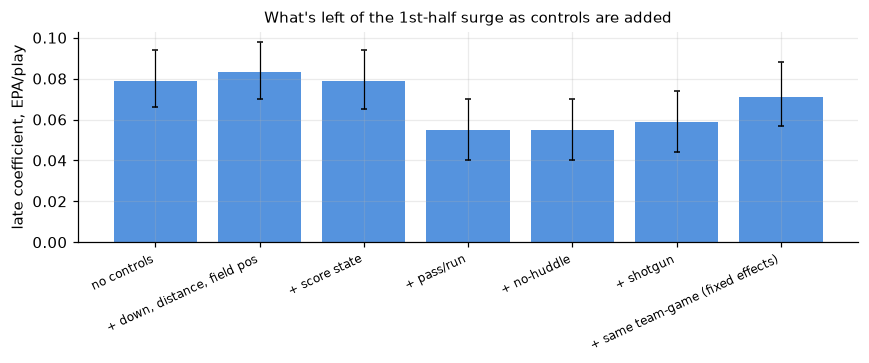

In [24]:
BASE = [("no controls", []), ("+ down, distance, field pos", ["dd", "fp"]), ("+ score state", ["state"]),
        ("+ pass/run", ["is_pass"]), ("+ no-huddle", ["nh"]), ("+ shotgun", ["shot"])]

def ladder(d, steps, fe=("game_id", "posteam", "game_half")):
    allc = [c for _, cs in steps for c in cs]
    d = d.dropna(subset=["epa"] + allc)
    out, ctrl, prev_dr, raw = [], [], None, None
    rungs = [(lab, cs, None) for lab, cs in steps] + [("+ same team-game (fixed effects)", [], list(fe))]
    for lab, cs, f in rungs:
        ctrl += cs
        r = ols_late(d, ctrl, fe=f)
        raw = r if raw is None else raw
        rem = r["draws"] / raw["draws"]
        row = {"step": lab, "late coef [95%]": ci(r),
               "% of raw left": f"{r['est'] / raw['est']:.0%} [{np.percentile(rem, 2.5):.0%}, {np.percentile(rem, 97.5):.0%}]"}
        if prev_dr is not None:
            inc = (prev_dr - r["draws"]) / raw["draws"]
            row["this step removes"] = f"{(prev_est - r['est']) / raw['est']:+.0%} [{np.percentile(inc, 2.5):+.0%}, {np.percentile(inc, 97.5):+.0%}]"
        out.append(row); prev_dr, prev_est, last = r["draws"], r["est"], r
    return pd.DataFrame(out).set_index("step"), raw, last

lad, raw_l, last_l = ladder(h1, BASE)
print(f"Ladder A: all seasons, n = {raw_l['n']:,}"); display(lad)
left = last_l["draws"] / raw_l["draws"]
log("Ladder", "share of surge left after all pbp controls + FE", last_l["est"] / raw_l["est"],
    *np.percentile(left, [2.5, 97.5]), kind="pct")

if HAVE_PART:
    ladB, rawB, _ = ladder(h1, BASE + [("+ personnel", ["pers"])])
    print(f"Ladder B: participation seasons, n = {rawB['n']:,}"); display(ladB)

fig, ax = plt.subplots(figsize=(8, 3.4))
est = [float(s.split()[0]) for s in lad["late coef [95%]"]]
lo = [float(s.split("[")[1].split(",")[0]) for s in lad["late coef [95%]"]]
hi = [float(s.split(", ")[1].rstrip("]")) for s in lad["late coef [95%]"]]
ax.bar(range(len(est)), est, color=BLUE, alpha=.8)
ax.errorbar(range(len(est)), est, yerr=[np.subtract(est, lo), np.subtract(hi, est)], fmt="none", color="black", lw=.8, capsize=2)
ax.set_xticks(range(len(est)), lad.index, rotation=25, ha="right", fontsize=8)
ax.set_ylabel("late coefficient, EPA/play"); ax.set_title("What's left of the 1st-half surge as controls are added", fontsize=10)
plt.tight_layout(); plt.show()

**Reading.** Down/distance/field position *raises* the gap slightly (106%) and score state brings it back to 100%. Pass/run removes 31% [25, 37], no-huddle 0%, shotgun −5%, personnel 0%. Same-team fixed effects add 16% back. **90% [81, 99] of the surge is left** after every measured football factor. Nothing on the field explains it, which is what we'd expect if it's valuation (Step 1b).

## Scoreboard
Every logged test in one table. `verdict` applies the pre-specified rule to explained shares only. Gap rows are judged by their own rule (written in `note` or in the pre-spec). Saved to `../results/phase3_scoreboard.csv` for the README.

In [25]:
sbd = pd.DataFrame(SB)
sbd["estimate [95%]"] = [
    "n/a" if not np.isfinite(e) else (f"{e:.0%} [{lo:.0%}, {hi:.0%}]" if k in ("share", "pct") else f"{e:+.3f} [{lo:+.3f}, {hi:+.3f}]")
    for e, lo, hi, k in zip(sbd["est"], sbd["lo"], sbd["hi"], sbd["kind"])]
display(sbd[["hyp", "test", "estimate [95%]", "verdict", "note"]])
Path("../results").mkdir(exist_ok=True)
sbd.drop(columns=["estimate [95%]"]).to_csv("../results/phase3_scoreboard.csv", index=False)

,hyp,test,estimate [95%],verdict,note
0,Claim A,1st-half EPA/play late - rest (re-derived),"+0.079 [+0.066, +0.094]",,
1,Step 1,"1st-half yards/play, late - rest","+0.011 [-0.080, +0.110]",,
2,Step 1,"1st-half first down or TD, late - rest","+0.014 [+0.009, +0.019]",,
3,Step 1,"1st-half success (yards vs down&dist), late - rest","+0.001 [-0.006, +0.008]",,
4,Step 1b,outcome mix share of EPA gap (real football part),"-23% [-47%, -2%]",ruled out,
5,H8,team-quality mix share,"0% [-2%, 2%]",ruled out,
6,H8,same team-game (fixed effects) share,"-0% [-5%, 4%]",ruled out,
7,H1,no-huddle mix share,"1% [-0%, 3%]",ruled out,
8,H1,surge on huddle-only plays (EPA),"+0.075 [+0.061, +0.091]",,
9,H1,tempo-tercile mix share,"3% [-3%, 9%]",ruled out,


## Phase 3 summary

1. **Is the surge real?** In value, yes; in performance, no. The +0.079 EPA gap is fully accounted for by how EPA prices the same outcome late (+0.096), while the actual outcome mix is slightly worse (−0.018). Raw yards and success are flat; turnovers, sacks and explosives are worse. The only raw improvement is first-down rate (+1.4 pts), which rises late in both halves.
2. **Is it composition?** No (0%).
3. **Which channels carry it?** None as performance. Ruled out: no-huddle/pace (1-3%), score state (6%), soft coverage (negative), personnel/formation (negative), defensive subs (link ii fails). Pass/run mix is a 23% contributor, best read as feeding the valuation effect. Timeouts go the opposite way to the prediction.
4. **Who gets more of it?** Nobody clearly. It's universal, which fits a valuation effect applied to everyone.
5. **How much is unexplained?** 90% after all football controls. Step 1b explains it: the stakes per play shrink late in the half.

**Reframe for Phase 4 (doc v1.6):** from "why do offenses surge late in the 1st half" to "the end-of-half surge is a valuation effect, not a performance one". Real things that remain:
- the 2nd-half leader drop (check it with Step 1b)
- offenses really do change behaviour late (faster, simpler, more and deeper passing) and defenses do too (softer, fewer subs), with no net raw gain
- the small first-down bump

Phase 4 asks what this means: clock-neutral EPA, re-testing Claims A/B on it, and guidance for analysts comparing EPA across game time.